In [ ]:
import os, glob
os.environ['R_HOME'] = '/home/caleb/miniconda3/envs/scFates/lib/R'
import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
np.random.seed(0)

In [ ]:
name = os.path.basename(os.getcwd())
pth = os.path.join('..', '..', '..', '..', '..', '..')
pth_in   = os.path.join(pth, 'data', 'cancer', 'vertebrate', 'CCCA', 'Claude', 'Head-and-Neck', name)
pth_feat = os.path.join(pth, 'data', 'features', 'biomart')
pth_fig  = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', 'Head-and-Neck', name)
pth_cb   = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_cb, exist_ok = True)

In [ ]:
adata = sc.read_h5ad(os.path.join(pth_in, 'manifold.h5ad'))
adata

In [ ]:
# manifold.h5ad already carries Gast/pSom/Crest (score_genes, gene_pool=union,
# ctrl_size matched, random_state=0) and their kNN-smoothed copies (_s), computed
# in nb02 to root the trajectory. Verify and (re)build smoothed if absent.
mods = ['Gast', 'pSom', 'Crest']
assert all(m in adata.obs for m in mods), 'module scores missing from manifold.h5ad'
if not all(m + '_s' in adata.obs for m in mods):
    C = adata.obsp['connectivities'] + sp.eye(adata.n_obs)
    Cn = sp.diags(1 / np.asarray(C.sum(1)).ravel()) @ C
    for m in mods:
        adata.obs[m + '_s'] = Cn @ adata.obs[m].values
print(adata.obs[mods].describe().round(3).to_string())

           Gast      pSom     Crest
count  3674.000  3674.000  3674.000
mean     -0.015     0.002    -0.007
std       0.034     0.029     0.031
min      -0.144    -0.111    -0.140
25%      -0.038    -0.016    -0.024
50%      -0.016     0.001    -0.005
75%       0.006     0.019     0.012
max       0.147     0.129     0.119


In [ ]:
# Pairwise module correlation across all malignant cells. Expected non-branching
# signature: Gast & pSom NON-negative (overlap), Crest anti-correlated with both.
print(adata.obs[mods].corr().round(3).to_string())

        Gast   pSom  Crest
Gast   1.000 -0.048 -0.541
pSom  -0.048  1.000 -0.438
Crest -0.541 -0.438  1.000


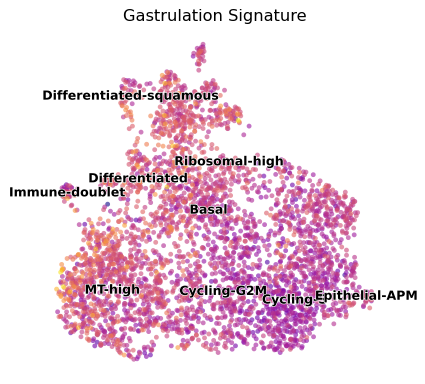

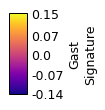

In [ ]:
def signature_fig(col, title, cb_label, cb_ticks, fname):
    fig, ax = plt.subplots(1, 1, figsize = (5, 5))
    sc.pl.umap(adata, color = col, cmap = 'plasma', alpha = .6, size = 60,
               colorbar_loc = None, frameon = False, show = False, ax = ax)
    sc.pl.umap(adata, color = 'subtype', size = 60, alpha = 0, legend_loc = 'on data',
               legend_fontoutline = 1, frameon = False, show = False, ax = ax)
    ax.set_title(title, size = 13)
    fig.savefig(os.path.join(pth_fig, fname), bbox_inches = 'tight')
    # colorbar
    cbf = plt.figure(figsize = (.66, 1)); cax = cbf.add_axes([.35, .05, .3, .9])
    cb = plt.colorbar(ax.collections[0], cax = cax); cb.ax.tick_params(which = 'both', size = 0)
    cb.set_label(cb_label); cb.set_ticks(cb_ticks, labels = cb_ticks); cb.solids.set_alpha(1)
    cbf.savefig(os.path.join(pth_cb, fname.replace('_signature', '_colorbar')), bbox_inches = 'tight')
    return fig

signature_fig('Gast', 'Gastrulation Signature', 'Gast\nSignature',
              np.round(np.linspace(adata.obs.Gast.min(), adata.obs.Gast.max(), 5), 2),
              'Gast_signature.pdf')

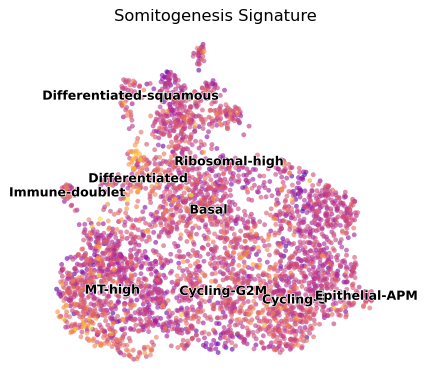

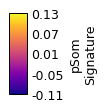

In [ ]:
signature_fig('pSom', 'Somitogenesis Signature', 'pSom\nSignature',
              np.round(np.linspace(adata.obs.pSom.min(), adata.obs.pSom.max(), 5), 2),
              'pSom_signature.pdf')

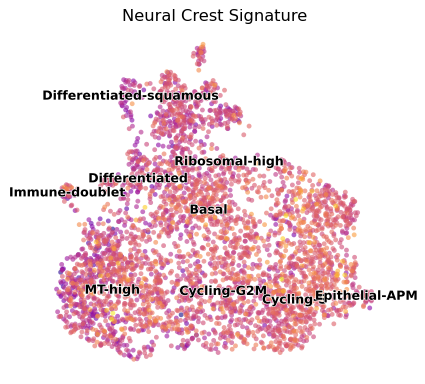

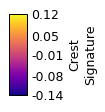

In [ ]:
signature_fig('Crest', 'Neural Crest Signature', 'Crest\nSignature',
              np.round(np.linspace(adata.obs.Crest.min(), adata.obs.Crest.max(), 5), 2),
              'Crest_signature.pdf')

In [ ]:
# ---- GATE 2 quantitative diagnostics ----
# (a) Cross-repression test: is the axis Gast-vs-pSom (branching) or (Gast/pSom)-vs-Crest
#     (non-branching)? Use per-principal-node cluster means so noise cancels.
R = np.asarray(adata.obsm['X_R']); node = R.argmax(1)
df = pd.DataFrame({'node': node, 'Gast': adata.obs.Gast_s.values,
                   'pSom': adata.obs.pSom_s.values, 'Crest': adata.obs.Crest_s.values})
sz = df.groupby('node').size(); keep = sz[sz >= 10].index
nm = df[df.node.isin(keep)].groupby('node')[['Gast','pSom','Crest']].mean()
r_gp = np.corrcoef(nm.Gast, nm.pSom)[0,1]
r_gc = np.corrcoef(nm.Gast, nm.Crest)[0,1]
r_pc = np.corrcoef(nm.pSom, nm.Crest)[0,1]
print(f'per-node-cluster corr  Gast~pSom = {r_gp:+.3f}   (>=0 => overlap, not cross-repression)')
print(f'per-node-cluster corr  Gast~Crest= {r_gc:+.3f}')
print(f'per-node-cluster corr  pSom~Crest= {r_pc:+.3f}')

# (b) Cycling confound (spec / Kurten lesson 2): is Gast a proliferation artifact?
sc.tl.score_genes_cell_cycle(adata,
    s_genes   = [g for g in ['MCM5','PCNA','TYMS','FEN1','MCM2','MCM4','RRM1','UNG','GINS2','MCM6','CDCA7','DTL','PRIM1','UHRF1','MLF1IP','HELLS','RFC2','RPA2','NASP','RAD51AP1','GMNN','WDR76','SLBP','CCNE2','UBR7','POLD3','MSH2','ATAD2','RAD51','RRM2','CDC45','CDC6','EXO1','TIPIN','DSCC1','BLM','CASP8AP2','USP1','CLSPN','POLA1','CHAF1B','BRIP1','E2F8'] if g in adata.var_names],
    g2m_genes = [g for g in ['HMGB2','CDK1','NUSAP1','UBE2C','BIRC5','TPX2','TOP2A','NDC80','CKS2','NUF2','CKS1B','MKI67','TMPO','CENPF','TACC3','FAM64A','SMC4','CCNB2','CKAP2L','CKAP2','AURKB','BUB1','KIF11','ANP32E','TUBB4B','GTSE1','KIF20B','HJURP','CDCA3','HN1','CDC20','TTK','CDC25C','KIF2C','RANGAP1','NCAPD2','DLGAP5','CDCA2','CDCA8','ECT2','KIF23','HMMR','AURKA','PSRC1','ANLN','LBR','CKAP5','CENPE','CTCF','NEK2','G2E3','GAS2L3','CBX5','CENPA'] if g in adata.var_names])
r_gS = np.corrcoef(adata.obs.S_score, adata.obs.Gast_s)[0,1]
r_gG = np.corrcoef(adata.obs.G2M_score, adata.obs.Gast_s)[0,1]
print(f'corr(Gast_s, S_score)   = {r_gS:+.3f}')
print(f'corr(Gast_s, G2M_score) = {r_gG:+.3f}   (>0 would flag proliferation-inflated Gast)')

# (c) developmental order along pseudotime
for m in mods:
    print(f'corr(t, {m}_s) = {np.corrcoef(adata.obs.t, adata.obs[m + "_s"])[0,1]:+.3f}')

per-node-cluster corr  Gast~pSom = +0.126   (>=0 => overlap, not cross-repression)
per-node-cluster corr  Gast~Crest= -0.817
per-node-cluster corr  pSom~Crest= -0.503
corr(Gast_s, S_score)   = -0.396
corr(Gast_s, G2M_score) = -0.491   (>0 would flag proliferation-inflated Gast)
corr(t, Gast_s) = -0.579
corr(t, pSom_s) = -0.106
corr(t, Crest_s) = +0.443


saved gate2_diagnostics.pdf


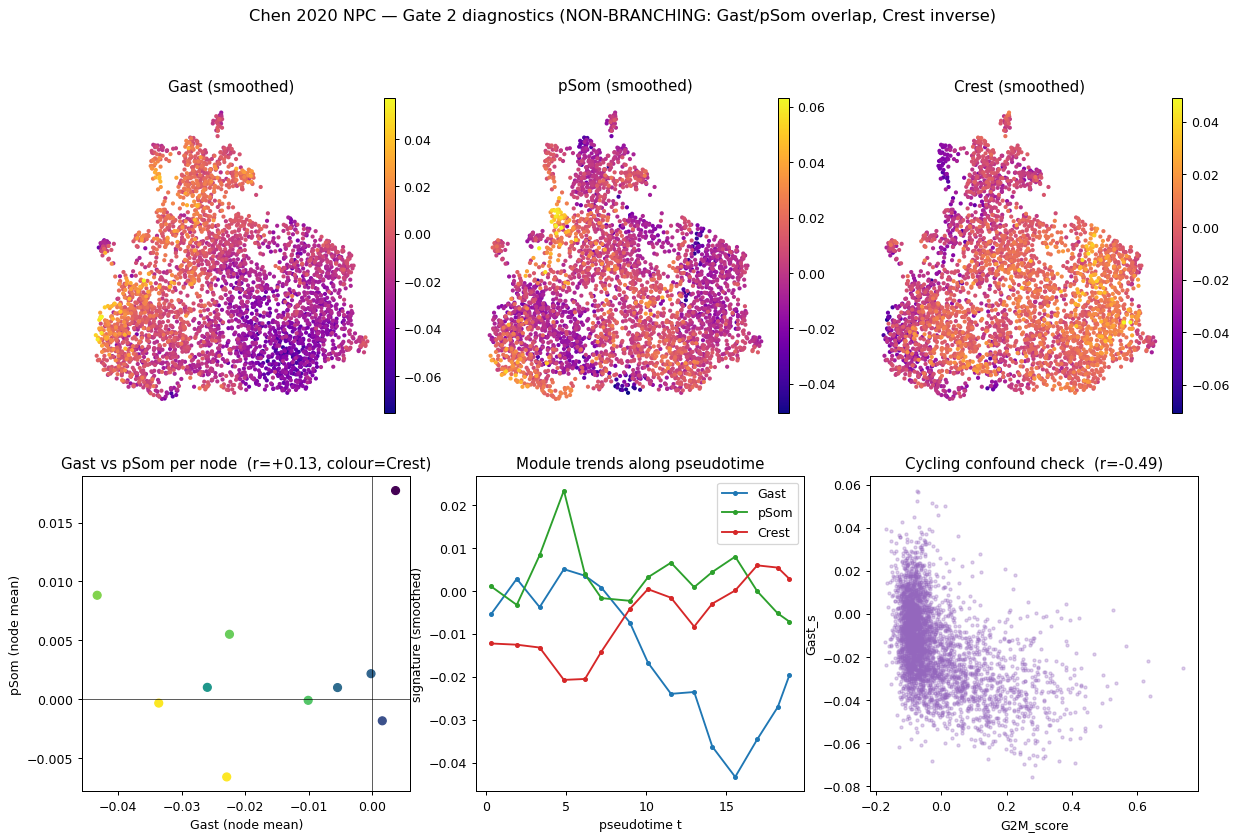

In [ ]:
fig, axes = plt.subplots(2, 3, figsize = (16, 10))
for ax, m in zip(axes[0], mods):
    sc.pl.umap(adata, color = m + '_s', cmap = 'plasma', size = 45, frameon = False,
               show = False, ax = ax, title = m + ' (smoothed)')
# cross-repression scatter (per-node cluster means)
axes[1,0].scatter(nm.Gast, nm.pSom, c = nm.Crest, cmap = 'viridis', s = 40)
axes[1,0].set_xlabel('Gast (node mean)'); axes[1,0].set_ylabel('pSom (node mean)')
axes[1,0].axhline(0, c='k', lw=.5); axes[1,0].axvline(0, c='k', lw=.5)
axes[1,0].set_title(f'Gast vs pSom per node  (r={r_gp:+.2f}, colour=Crest)')
# pseudotime trends
o = adata.obs.sort_values('t')
b = np.linspace(o.t.min(), o.t.max(), 15); idx = np.digitize(o.t, b)
for m, c in zip(mods, ['tab:blue','tab:green','tab:red']):
    bm = o.groupby(idx)[m + '_s'].mean(); bt = o.groupby(idx)['t'].mean()
    axes[1,1].plot(bt, bm, marker='o', ms=3, c=c, label=m)
axes[1,1].set_xlabel('pseudotime t'); axes[1,1].set_ylabel('signature (smoothed)')
axes[1,1].legend(); axes[1,1].set_title('Module trends along pseudotime')
# cycling confound
axes[1,2].scatter(adata.obs.G2M_score, adata.obs.Gast_s, s=6, alpha=.3, c='tab:purple')
axes[1,2].set_xlabel('G2M_score'); axes[1,2].set_ylabel('Gast_s')
axes[1,2].set_title(f'Cycling confound check  (r={r_gG:+.2f})')
fig.suptitle('Chen 2020 NPC — Gate 2 diagnostics (NON-BRANCHING: Gast/pSom overlap, Crest inverse)', size=13)
fig.savefig(os.path.join(pth_fig, 'gate2_diagnostics.pdf'), bbox_inches='tight')
print('saved gate2_diagnostics.pdf')

In [ ]:
# ---- GATE 2 VERDICT ----
verdict = {
    'gate2': 'GO',
    'topology': 'non-branching',
    'basis': 'Gast/pSom co-vary (per-node r={:+.2f} >= 0) = OVERLAP not cross-repression; '
             'Crest is inverse/terminal gradient (Gast~Crest {:+.2f}, pSom~Crest {:+.2f}); '
             'curve pseudotime runs Gast/pSom-high progenitor -> Crest-high terminus.'.format(r_gp, r_gc, r_pc),
    'cross_repression_gastvspSom': float(r_gp),
    'cycling_confound_flag': bool(r_gG > 0.1),
    'cycling_note': 'Gast anti-correlates with cell cycle (G2M r={:+.2f}) -> progenitor is quiescent, '
                    'NOT a proliferation artifact (opposite of Kurten inflation).'.format(r_gG),
    'crest_on_gast_arm_flag': False,   # no arms; single axis
    'gate3': 'NA (non-branching -> no bifurcation to test for cross-repression)',
}
adata.uns['gate2'] = verdict
for k, v in verdict.items():
    print(f'{k}: {v}')
adata.write(os.path.join(pth_in, 'signatures.h5ad'))
print('\nsaved signatures.h5ad', adata.shape)

gate2: GO
topology: non-branching
basis: Gast/pSom co-vary (per-node r=+0.13 >= 0) = OVERLAP not cross-repression; Crest is inverse/terminal gradient (Gast~Crest -0.82, pSom~Crest -0.50); curve pseudotime runs Gast/pSom-high progenitor -> Crest-high terminus.
cross_repression_gastvspSom: 0.12569784469550777
cycling_confound_flag: False
cycling_note: Gast anti-correlates with cell cycle (G2M r=-0.49) -> progenitor is quiescent, NOT a proliferation artifact (opposite of Kurten inflation).
crest_on_gast_arm_flag: False
gate3: NA (non-branching -> no bifurcation to test for cross-repression)

saved signatures.h5ad (3674, 22080)
